# Statistical and Machine Learning — HW1 : Introduction and Learnability

**Université de Haute-Alsace — M2 Informatique et Mobilité**

**Module :** Statistical and Machine Learning

**Teacher :** Ali El Hadi ISMAIL FAWAZ

**Student :** Zainab ELAMRI

---

## Objective

This notebook experimentally illustrates the difference between the **PAC** (realizable) and the **Agnostic PAC** learning frameworks.

We implement, without any ML library, an **Empirical Risk Minimization (ERM)** algorithm over the class of threshold classifiers on $\mathcal{X} = [0,1]$:

$$\mathcal{H} = \{ h_t : x \mapsto \mathbb{1}[x > t] \;,\; t \in [0,1] \}, \qquad f_\theta(x) = \mathbb{1}[x > \theta].$$

* **Realizable setting:** $y = f_\theta(x)$, so $f_\theta \in \mathcal{H}$ and $\min_{h\in\mathcal{H}} L_{\mathcal{D}}(h) = 0$.
* **Agnostic setting:** each label is independently flipped with probability $\eta$, so no hypothesis can be perfect.

**Notation.** $S$ is a training sample of size $m$, $L_S(h)$ the empirical error, $L_{\mathcal{D}}(h)$ (written $L(h)$) the true error, $h_S = \mathrm{ERM}_{\mathcal{H}}(S)$.

### Plan

0. Setup and experimental design
1. Data generation
2. Implementation of ERM
3. Performance evaluation
4. Experimental verification of PAC learning
5. From PAC to Agnostic PAC
6. Conclusion

## 0. Setup and experimental design

### Choice of the parameters

| Parameter | Value | Justification |
|---|---|---|
| Target threshold $\theta$ | $0.37$ | Not $0.5$ to avoid a symmetric problem; $[\theta-\varepsilon,\theta+\varepsilon] \subset [0,1]$ so the PAC bound below applies exactly. |
| Accuracy $\varepsilon$ | $0.05$ | A 5 % error tolerance: small enough to be demanding for $m=5$ or $10$, reachable for $m \ge 50$. |
| Confidence $\delta$ | $0.05$ | We require the "bad event" $L(h_S) > \varepsilon$ to happen in at most 5 % of the runs. |
| Noise rate $\eta$ | $0.2$ (main), $\{0.1, 0.2, 0.3\}$ (sweep) | $\eta = 0.2 > \varepsilon$ makes the difference between both settings very visible; the sweep shows the effect of the noise level. $\eta < 0.5$ is needed, otherwise labels carry no information. |
| Sample sizes $m$ | $\{5,10,20,50,100,200\}$ (+ $500, 1000, 2000$ for the agnostic part) | Imposed sizes; larger sizes are added in Section 5 to observe the asymptotic behaviour under noise. |
| Repetitions $N$ | $1000$ | The standard error of an estimated probability is $\le \sqrt{0.25/1000} \approx 0.016$. |
| Test set size | $200\,000$ | Standard error of the true-error estimate $\le \sqrt{0.25/200000} \approx 0.001$, negligible compared to $\varepsilon$. |

A fixed random seed makes every result reproducible.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

SEED = 42
rng = np.random.default_rng(SEED)

THETA  = 0.37                       # target threshold
EPS    = 0.05                       # accuracy parameter
DELTA  = 0.05                       # confidence parameter
ETA    = 0.2                        # main label-noise rate (agnostic setting)
ETAS   = [0.1, 0.2, 0.3]            # noise rates for the sweep
M_LIST = [5, 10, 20, 50, 100, 200]  # imposed training sizes
M_EXT  = M_LIST + [500, 1000, 2000] # extended sizes for the agnostic setting
N_REP  = 1000                       # repetitions per training size
N_TEST = 200_000                    # size of the independent test set

## 1. Data generation

Points are drawn uniformly on $[0,1]$. Labels are given by $f_\theta$, then — in the agnostic setting only — each label is flipped independently with probability $\eta$ (the flipped labels are returned as well, to be able to visualise them).

In [2]:
def target(x, theta=THETA):
    '''Target threshold classifier f_theta(x) = 1[x > theta].'''
    return (x > theta).astype(int)


def generate_data(m, eta=0.0, rng=rng, theta=THETA):
    '''
    Draw m i.i.d. examples: x ~ U[0,1], y = f_theta(x), each label flipped with prob. eta.
    eta = 0 -> realizable setting, eta > 0 -> agnostic setting.
    Returns x, y and the boolean mask of flipped labels.
    '''
    x = rng.uniform(0.0, 1.0, size=m)
    y = target(x, theta)
    flipped = rng.uniform(0.0, 1.0, size=m) < eta
    y = np.where(flipped, 1 - y, y)
    return x, y, flipped


# One training set for every required size (realizable setting)
datasets = {m: generate_data(m) for m in M_LIST}
for m, (x, y, _) in datasets.items():
    print(f"m = {m:>3} : {y.sum():>3} positive / {m - y.sum():>3} negative examples")

m =   5 :   4 positive /   1 negative examples
m =  10 :   8 positive /   2 negative examples
m =  20 :  13 positive /   7 negative examples
m =  50 :  30 positive /  20 negative examples
m = 100 :  59 positive /  41 negative examples
m = 200 : 125 positive /  75 negative examples


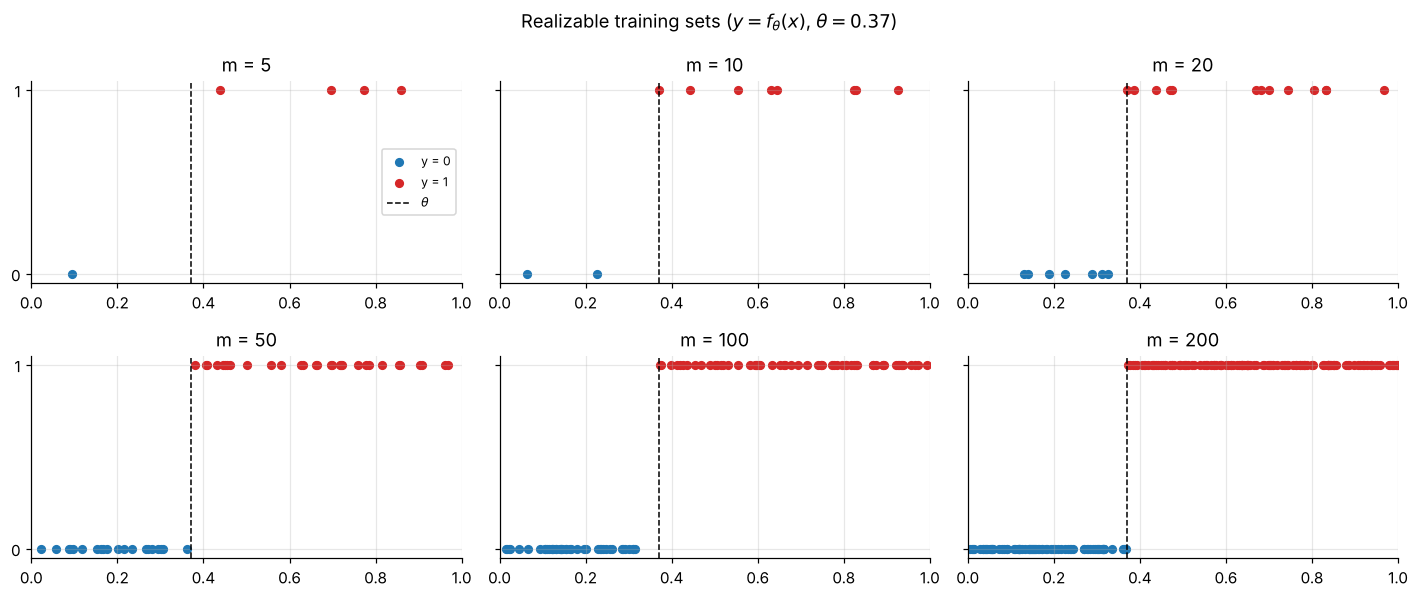

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5.5), sharey=True)
for ax, m in zip(axes.ravel(), M_LIST):
    x, y, _ = datasets[m]
    ax.scatter(x[y == 0], y[y == 0], c="tab:blue", s=25, label="y = 0")
    ax.scatter(x[y == 1], y[y == 1], c="tab:red",  s=25, label="y = 1")
    ax.axvline(THETA, color="k", ls="--", lw=1, label=r"$\theta$")
    ax.set_title(f"m = {m}"); ax.set_xlim(0, 1); ax.set_yticks([0, 1])
axes[0, 0].legend(loc="center right", fontsize=8)
fig.suptitle(r"Realizable training sets ($y = f_\theta(x)$, $\theta = 0.37$)")
plt.tight_layout(); plt.show()

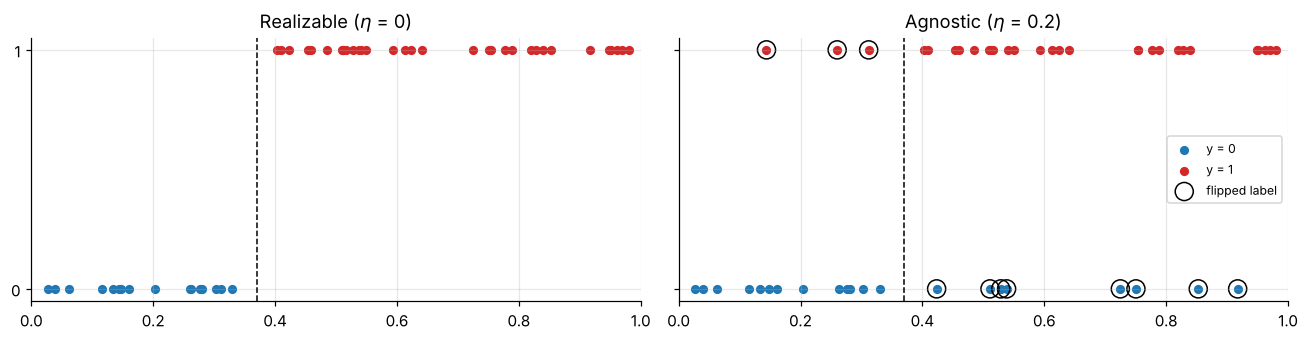

11 labels out of 50 were flipped (22%, expected 20%).


In [4]:
# Realizable vs noisy dataset with the same inputs (m = 50)
rng_vis = np.random.default_rng(1)
x_vis = rng_vis.uniform(0, 1, 50)
y_clean = target(x_vis)
flip = rng_vis.uniform(0, 1, 50) < ETA
y_noisy = np.where(flip, 1 - y_clean, y_clean)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for ax, y, title in [(axes[0], y_clean, "Realizable ($\\eta$ = 0)"),
                     (axes[1], y_noisy, f"Agnostic ($\\eta$ = {ETA})")]:
    ax.scatter(x_vis[y == 0], y[y == 0], c="tab:blue", s=25, label="y = 0")
    ax.scatter(x_vis[y == 1], y[y == 1], c="tab:red", s=25, label="y = 1")
    ax.axvline(THETA, color="k", ls="--", lw=1)
    ax.set_title(title); ax.set_yticks([0, 1]); ax.set_xlim(0, 1)
axes[1].scatter(x_vis[flip], y_noisy[flip], s=140, facecolors="none",
                edgecolors="k", label="flipped label")
axes[1].legend(fontsize=8, loc="center right")
plt.tight_layout(); plt.show()
print(f"{flip.sum()} labels out of 50 were flipped ({flip.mean():.0%}, expected {ETA:.0%}).")

**Interpretation.** In the realizable setting all points left of $\theta$ are labelled 0 and all points right of $\theta$ are labelled 1: a perfect threshold always exists, located between the largest negative point and the smallest positive point. For small $m$ (5, 10) this interval is wide, so the position of $\theta$ is poorly determined; it shrinks as $m$ grows.
With noise, some red points appear left of $\theta$ and some blue points right of it (circled): no threshold separates the two classes perfectly anymore.

## 2. Implementation of ERM

### Strategy

The empirical error of $h_t$ is
$$L_S(h_t) = \frac{1}{m}\sum_{i=1}^m \mathbb{1}[h_t(x_i) \neq y_i] = \frac{1}{m}\Big( \#\{i : x_i \le t,\ y_i = 1\} + \#\{i : x_i > t,\ y_i = 0\} \Big).$$

Although $t$ takes infinitely many values, $L_S(h_t)$ is **piecewise constant**: it can only change when $t$ crosses a training point. Sorting the sample $x_{(1)} \le \dots \le x_{(m)}$, there are only $m+1$ distinct behaviours, indexed by $k \in \{0,\dots,m\}$ = number of points classified 0:

$$\text{err}(k) = \underbrace{\#\{\,i \le k : y_{(i)} = 1\,\}}_{\text{positives predicted 0}} + \underbrace{\#\{\,i > k : y_{(i)} = 0\,\}}_{\text{negatives predicted 1}}.$$

Both terms are obtained for all $k$ at once with **cumulative sums**, so ERM is **exact** and costs $O(m \log m)$ (dominated by the sort), instead of a grid search which would be approximate.

**Tie-breaking.** Every $t \in [x_{(k)}, x_{(k+1)})$ has the same empirical error. We return the **midpoint** $\hat t = (x_{(k)} + x_{(k+1)})/2$ (with $x_{(0)} = 0$, $x_{(m+1)} = 1$): it is still an ERM, and it stays as far as possible from both observed classes. If several $k$ reach the minimum, the first one is kept.

In [5]:
def erm_threshold(x, y):
    '''
    Exact ERM over H = {h_t(x) = 1[x > t]}.
    Returns the selected threshold t_hat (midpoint of the optimal interval)
    and its empirical error L_S(h_t_hat).
    '''
    m = len(x)
    order = np.argsort(x)
    xs, ys = x[order], y[order]

    k = np.arange(m + 1)                                   # k = number of points predicted 0
    pos_left  = np.concatenate(([0], np.cumsum(ys)))        # positives among the k smallest
    neg_left  = k - pos_left                                # negatives among the k smallest
    neg_right = (m - ys.sum()) - neg_left                   # negatives among the m-k largest
    errors = pos_left + neg_right

    k_best = int(np.argmin(errors))
    left  = 0.0 if k_best == 0 else xs[k_best - 1]
    right = 1.0 if k_best == m else xs[k_best]
    return 0.5 * (left + right), errors[k_best] / m


def empirical_error(t, x, y):
    '''L_S(h_t): fraction of misclassified training points.'''
    return np.mean((x > t).astype(int) != y)

**Correctness check.** We compare our exact ERM with a brute-force search over a fine grid of 10 001 thresholds on random noisy samples: the minimal empirical error must be identical (the grid can only be equal or worse).

In [6]:
grid = np.linspace(0, 1, 10_001)
rng_check = np.random.default_rng(7)
n_equal = n_grid_worse = n_wrong = 0
for _ in range(300):
    m = rng_check.integers(5, 200)
    x, y, _ = generate_data(m, eta=0.25, rng=rng_check)
    t_hat, e_hat = erm_threshold(x, y)
    e_grid = np.min([(np.mean((x > t).astype(int) != y)) for t in grid])
    if not np.isclose(e_hat, empirical_error(t_hat, x, y)) or e_hat > e_grid + 1e-12:
        n_wrong += 1                      # our ERM would be beaten by the grid -> bug
    elif np.isclose(e_hat, e_grid):
        n_equal += 1
    else:
        n_grid_worse += 1                 # grid missed the optimal interval
print(f"Same minimum as brute force          : {n_equal} / 300")
print(f"Strictly better than the 10001-grid  : {n_grid_worse} / 300")
print(f"Worse than the grid (would be a bug) : {n_wrong} / 300")

Same minimum as brute force          : 299 / 300
Strictly better than the 10001-grid  : 1 / 300
Worse than the grid (would be a bug) : 0 / 300


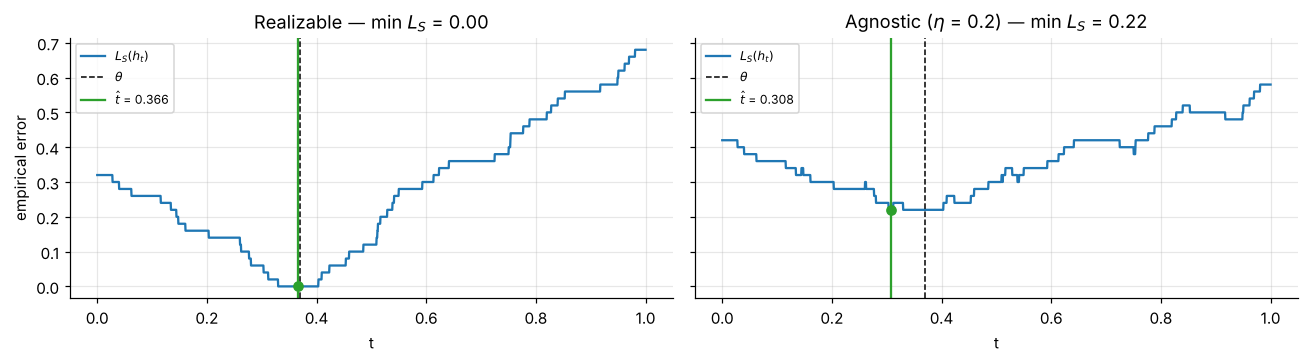

In [7]:
# Empirical error as a function of t, realizable vs noisy (same 50 inputs as above)
ts = np.linspace(0, 1, 2001)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, y, title in [(axes[0], y_clean, "Realizable"), (axes[1], y_noisy, f"Agnostic ($\\eta$ = {ETA})")]:
    curve = [empirical_error(t, x_vis, y) for t in ts]
    t_hat, e_hat = erm_threshold(x_vis, y)
    ax.plot(ts, curve, lw=1.5, label=r"$L_S(h_t)$")
    ax.axvline(THETA, color="k", ls="--", lw=1, label=r"$\theta$")
    ax.axvline(t_hat, color="tab:green", lw=1.5, label=rf"$\hat t$ = {t_hat:.3f}")
    ax.scatter([t_hat], [e_hat], color="tab:green", zorder=3)
    ax.set_title(f"{title} — min $L_S$ = {e_hat:.2f}"); ax.set_xlabel("t")
    ax.legend(fontsize=8)
axes[0].set_ylabel("empirical error")
plt.tight_layout(); plt.show()

**Interpretation.** Our ERM is never beaten by the brute-force search; it reaches the same minimum in almost every case and is *strictly better* when two training points are closer than the grid step ($10^{-4}$): the grid then misses the optimal interval, whereas the sorting-based search is exact (and much faster).
The curves confirm that $L_S(h_t)$ is a step function. In the realizable case its minimum is exactly 0 on a whole interval containing $\theta$, and $\hat t$ is its midpoint. In the noisy case the minimum is strictly positive (each flipped label near the boundary costs one error whatever $t$), and the curve is much flatter around its minimum: the location of the best threshold is less clearly identified by the data.

## 3. Performance evaluation

* **Empirical error** $L_S(h_S)$: computed on the training set.
* **True error** $L_{\mathcal{D}}(h_S)$: estimated on an **independent test set** of $200\,000$ points drawn from the same distribution (with noisy labels in the agnostic setting, since $\mathcal{D}$ includes the noise).

Evaluating each hypothesis naively would cost $O(n_\text{test})$; since $h_t$ is a threshold, we sort the test set once and use binary search + prefix counts, so each evaluation costs $O(\log n_\text{test})$ — this makes the 1000-repetition experiments fast.

**Sanity check with the closed form.** Because $x$ is uniform, $h_t$ and $f_\theta$ disagree exactly on the interval between $t$ and $\theta$, hence
$$L^{\text{real}}(h_t) = |t-\theta|, \qquad L^{\text{agn}}(h_t) = \eta + (1-2\eta)\,|t-\theta|.$$
(A point in the disagreement interval is wrong unless its label was flipped, a point outside is wrong only if flipped.) We use these formulas only to **validate** the test-set estimates.

In [8]:
class TestSet:
    '''Large independent test set, sorted once for fast evaluation of threshold classifiers.'''
    def __init__(self, n, eta, rng):
        x, y, _ = generate_data(n, eta, rng)
        order = np.argsort(x)
        self.x, self.y, self.n = x[order], y[order], n
        self.pos_prefix = np.concatenate(([0], np.cumsum(self.y)))   # positives among the k smallest
        self.n_neg = n - self.y.sum()

    def error(self, t):
        '''Test error of h_t (vectorised over t).'''
        k = np.searchsorted(self.x, t, side="right")                 # number of points predicted 0
        pos_left = self.pos_prefix[k]
        neg_right = self.n_neg - (k - pos_left)
        return (pos_left + neg_right) / self.n


def true_error_closed_form(t, eta=0.0):
    return eta + (1 - 2 * eta) * np.abs(t - THETA)


test_real = TestSet(N_TEST, 0.0, rng)
ts_check = rng.uniform(0, 1, 1000)
print("max |test estimate - closed form| (realizable):",
      np.abs(test_real.error(ts_check) - true_error_closed_form(ts_check)).max().round(4))

max |test estimate - closed form| (realizable): 0.0011


In [9]:
print(f"{'m':>5} | {'t_hat':>7} | {'L_S(h)':>7} | {'L_D(h) test':>11} | {'L_D(h) exact':>12} | gap")
print("-" * 62)
single = {}
for m in M_LIST:
    x, y, _ = datasets[m]
    t_hat, e_emp = erm_threshold(x, y)
    e_true = test_real.error(t_hat)
    single[m] = (e_emp, e_true)
    print(f"{m:>5} | {t_hat:7.4f} | {e_emp:7.4f} | {e_true:11.4f} | "
          f"{true_error_closed_form(t_hat):12.4f} | {e_true - e_emp:.4f}")

    m |   t_hat |  L_S(h) | L_D(h) test | L_D(h) exact | gap
--------------------------------------------------------------
    5 |  0.2665 |  0.0000 |      0.1026 |       0.1035 | 0.1026
   10 |  0.2990 |  0.0000 |      0.0704 |       0.0710 | 0.0704
   20 |  0.3481 |  0.0000 |      0.0221 |       0.0219 | 0.0221
   50 |  0.3714 |  0.0000 |      0.0014 |       0.0014 | 0.0014
  100 |  0.3448 |  0.0000 |      0.0255 |       0.0252 | 0.0255
  200 |  0.3694 |  0.0000 |      0.0005 |       0.0006 | 0.0005


A single training set is subject to chance, so we also average over $N = 1000$ independent training sets per size. The function below is reused for every experiment of the notebook.

In [10]:
def run_experiment(m_list, eta, n_rep=N_REP, n_test=N_TEST, rng=rng):
    '''
    For each m: draw n_rep training sets, run ERM, record the empirical error
    and the true error (on one large independent test set).
    Returns a dict  m -> {"emp", "true", "t": arrays of size n_rep, "best": test error of h_theta}.
    '''
    test = TestSet(n_test, eta, rng)
    results = {}
    for m in m_list:
        t_hat = np.empty(n_rep); emp = np.empty(n_rep)
        for r in range(n_rep):
            x, y, _ = generate_data(m, eta, rng)
            t_hat[r], emp[r] = erm_threshold(x, y)
        results[m] = {"t": t_hat, "emp": emp, "true": test.error(t_hat),
                      "best": test.error(THETA)}   # error of the best hypothesis h_theta on the same test set
    return results


res_real = run_experiment(M_LIST, eta=0.0)
print(f"{'m':>5} | {'mean L_S':>8} | {'mean L_D':>8} | {'std L_D':>7} | {'max L_D':>7}")
for m in M_LIST:
    r = res_real[m]
    print(f"{m:>5} | {r['emp'].mean():8.4f} | {r['true'].mean():8.4f} | "
          f"{r['true'].std():7.4f} | {r['true'].max():7.4f}")

    m | mean L_S | mean L_D | std L_D | max L_D
    5 |   0.0000 |   0.0746 |  0.0607 |  0.3155
   10 |   0.0000 |   0.0454 |  0.0418 |  0.2468
   20 |   0.0000 |   0.0241 |  0.0237 |  0.1645
   50 |   0.0000 |   0.0103 |  0.0104 |  0.0692
  100 |   0.0000 |   0.0048 |  0.0047 |  0.0338
  200 |   0.0000 |   0.0025 |  0.0027 |  0.0199


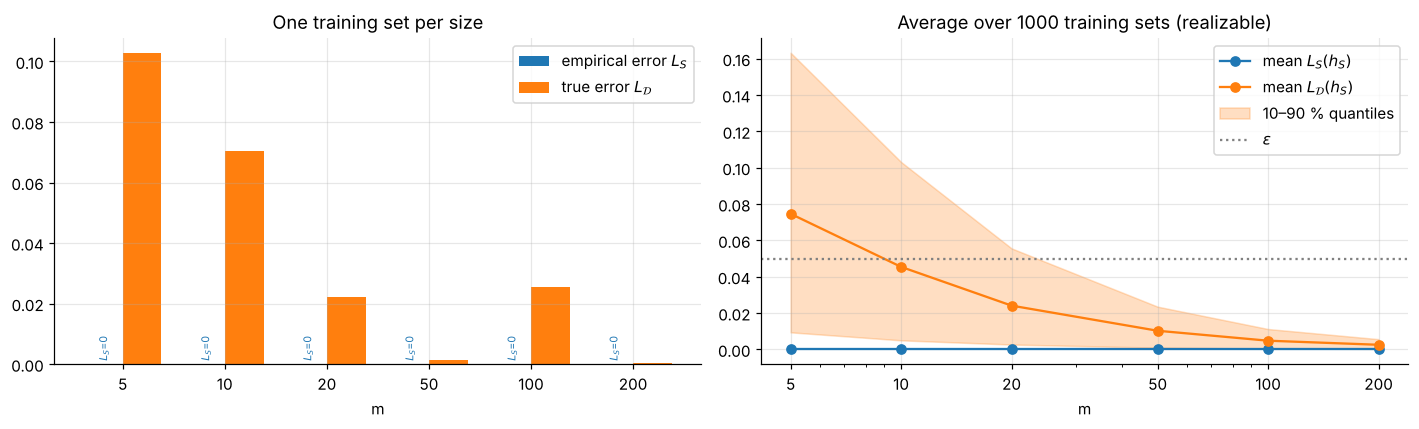

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
idx = np.arange(len(M_LIST)); w = 0.38
axes[0].bar(idx - w/2, [single[m][0] for m in M_LIST], w, label=r"empirical error $L_S$")
axes[0].bar(idx + w/2, [single[m][1] for m in M_LIST], w, label=r"true error $L_{\mathcal{D}}$")
for i in idx:
    axes[0].text(i - w/2, 0.002, r"$L_S$=0", ha="center", fontsize=7, rotation=90, color="tab:blue")
axes[0].set_xticks(idx, M_LIST); axes[0].set_xlabel("m")
axes[0].set_title("One training set per size"); axes[0].legend()

mean_true = np.array([res_real[m]["true"].mean() for m in M_LIST])
q10, q90 = (np.array([np.quantile(res_real[m]["true"], q) for m in M_LIST]) for q in (0.1, 0.9))
axes[1].plot(M_LIST, [res_real[m]["emp"].mean() for m in M_LIST], "o-", label=r"mean $L_S(h_S)$")
axes[1].plot(M_LIST, mean_true, "o-", label=r"mean $L_{\mathcal{D}}(h_S)$")
axes[1].fill_between(M_LIST, q10, q90, alpha=0.25, color="tab:orange", label="10–90 % quantiles")
axes[1].axhline(EPS, color="gray", ls=":", label=r"$\varepsilon$")
axes[1].set_xscale("log"); axes[1].set_xticks(M_LIST, M_LIST); axes[1].set_xlabel("m")
axes[1].set_title(f"Average over {N_REP} training sets (realizable)"); axes[1].legend()
plt.tight_layout(); plt.show()

**Interpretation.**

* The test-set estimate agrees with the closed form up to $\approx 10^{-3}$, so $200\,000$ test points are indeed "sufficiently large".
* On a **single** training set the true error is not monotone in $m$ (here $m = 100$ does worse than $m = 50$): it depends on where the points closest to $\theta$ happen to fall. This is why the statements of learning theory are probabilistic, and why we average over many training sets.
* In the realizable setting the **empirical error is always exactly 0**: ERM always finds a threshold consistent with the sample, because $f_\theta \in \mathcal{H}$.
* The empirical error is therefore an **optimistic** estimate: the true error is positive, and the gap $L_{\mathcal{D}}(h_S) - L_S(h_S)$ is entirely due to the uncertainty on the position of $\theta$ between the two closest training points of opposite classes.
* This gap shrinks quickly: the mean true error roughly halves each time $m$ doubles ($\approx 0.5/m$ here, since the gap between two consecutive uniform points is of order $1/m$), and the dispersion between training sets shrinks too.

## 4. Experimental verification of PAC learning

A class is **PAC learnable** if for all $\varepsilon, \delta \in (0,1)$ there is $m_{\mathcal{H}}(\varepsilon,\delta)$ such that for every $m \ge m_{\mathcal{H}}(\varepsilon,\delta)$ and in the realizable case:
$$\Pr_{S\sim\mathcal{D}^m}\big(L_{\mathcal{D}}(h_S) > \varepsilon\big) \le \delta .$$

We estimate this probability by the frequency of runs where $L_{\mathcal{D}}(h_S) > \varepsilon$ over the $N = 1000$ repetitions.

**Theoretical bound for thresholds.** Any consistent ERM returns $t \in [x_{\text{left}}, x_{\text{right}})$, where $x_\text{left}$ (resp. $x_\text{right}$) is the largest negative (resp. smallest positive) training point. $|t-\theta| > \varepsilon$ requires that no training point falls in $(\theta, \theta+\varepsilon]$ or none in $[\theta-\varepsilon, \theta]$, each with probability $(1-\varepsilon)^m$, so
$$\Pr\big(L(h_S) > \varepsilon\big) \le 2(1-\varepsilon)^m \le 2e^{-\varepsilon m} \quad\Rightarrow\quad m_{\mathcal{H}}(\varepsilon,\delta) \le \left\lceil \frac{\ln(2/\delta)}{\varepsilon} \right\rceil .$$

In [12]:
m_theory = int(np.ceil(np.log(2 / DELTA) / EPS))
p_bad_real = np.array([(res_real[m]["true"] > EPS).mean() for m in M_LIST])
bound = np.minimum(1, 2 * (1 - EPS) ** np.array(M_LIST))

print(f"Theoretical sample complexity for eps={EPS}, delta={DELTA} : m >= {m_theory}\n")
print(f"{'m':>5} | {'Pr(L>eps) estimated':>20} | {'bound 2(1-eps)^m':>16} | <= delta ?")
for m, p, b in zip(M_LIST, p_bad_real, bound):
    print(f"{m:>5} | {p:20.3f} | {b:16.3f} | {'yes' if p <= DELTA else 'no'}")

Theoretical sample complexity for eps=0.05, delta=0.05 : m >= 74

    m |  Pr(L>eps) estimated | bound 2(1-eps)^m | <= delta ?
    5 |                0.565 |            1.000 | no
   10 |                0.350 |            1.000 | no
   20 |                0.126 |            0.717 | no
   50 |                0.010 |            0.154 | yes
  100 |                0.000 |            0.012 | yes
  200 |                0.000 |            0.000 | yes


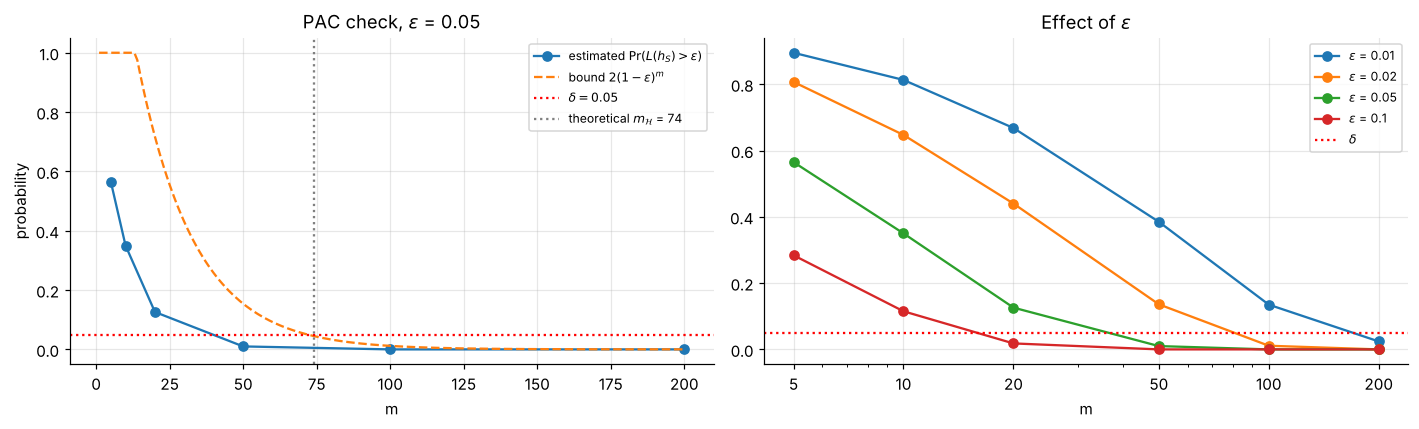

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.plot(M_LIST, p_bad_real, "o-", label=r"estimated $\Pr(L(h_S) > \varepsilon)$")
m_fine = np.arange(1, 201)
ax.plot(m_fine, np.minimum(1, 2 * (1 - EPS) ** m_fine), "--", label=r"bound $2(1-\varepsilon)^m$")
ax.axhline(DELTA, color="red", ls=":", label=r"$\delta = 0.05$")
ax.axvline(m_theory, color="gray", ls=":", label=rf"theoretical $m_\mathcal{{H}}$ = {m_theory}")
ax.set_xlabel("m"); ax.set_ylabel("probability"); ax.set_title(rf"PAC check, $\varepsilon$ = {EPS}")
ax.legend(fontsize=8)

# Several accuracy levels (same simulations)
ax = axes[1]
for eps in [0.01, 0.02, 0.05, 0.1]:
    ax.plot(M_LIST, [(res_real[m]["true"] > eps).mean() for m in M_LIST], "o-", label=rf"$\varepsilon$ = {eps}")
ax.axhline(DELTA, color="red", ls=":", label=r"$\delta$")
ax.set_xscale("log"); ax.set_xticks(M_LIST, M_LIST); ax.set_xlabel("m")
ax.set_title(r"Effect of $\varepsilon$"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

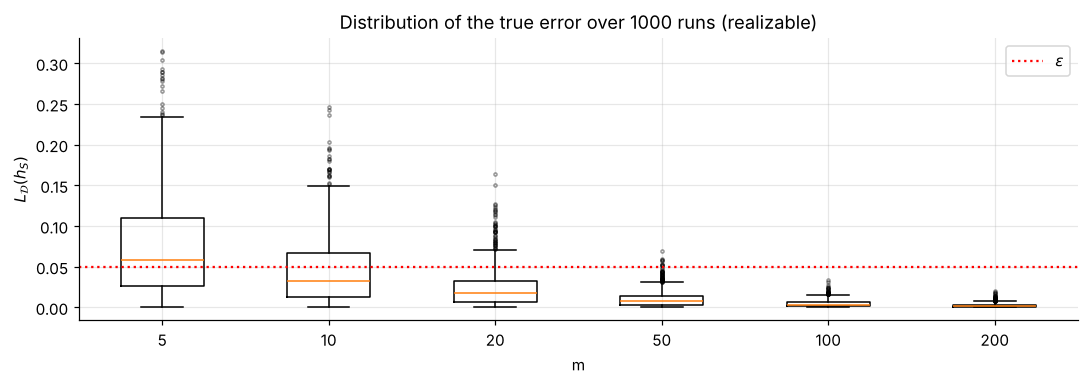

In [14]:
# Distribution of the true error for each m
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.boxplot([res_real[m]["true"] for m in M_LIST], tick_labels=M_LIST, showfliers=True,
           flierprops=dict(markersize=2, alpha=0.4))
ax.axhline(EPS, color="red", ls=":", label=r"$\varepsilon$")
ax.set_xlabel("m"); ax.set_ylabel(r"$L_{\mathcal{D}}(h_S)$")
ax.set_title(f"Distribution of the true error over {N_REP} runs (realizable)"); ax.legend()
plt.tight_layout(); plt.show()

**Interpretation.**

* The probability of a "bad" hypothesis ($L > \varepsilon$) **decreases very fast** with $m$ (exponentially, as predicted): from about 0.6 for $m = 5$ to 0 for $m \ge 100$. The requirement $\Pr(L>\varepsilon)\le\delta$ is already met from $m = 50$.
* The estimated curve always stays **below the theoretical bound** $2(1-\varepsilon)^m$, as it should. The bound is pessimistic (it only uses $m \ge 74$ for our $(\varepsilon,\delta)$): it holds for every distribution and every consistent ERM, while our midpoint rule and the uniform distribution are favourable. Note that the bound does not depend on $\theta$ nor on the distribution: this is what makes PAC guarantees *distribution-free*.
* A smaller $\varepsilon$ shifts the curve to the right: more examples are needed for a more demanding accuracy (consistent with $m_{\mathcal{H}} \propto 1/\varepsilon$).
* The boxplots show the whole error distribution concentrating towards 0: both the typical error and its variability decrease.

**Conclusion of Section 4:** the class of thresholds is PAC learnable and ERM is a successful PAC learner in the realizable case.

## 5. From PAC to Agnostic PAC

We now flip each label independently with probability $\eta$ (training **and** test labels, since the noise is part of the distribution $\mathcal{D}$). The target $f_\theta$ is still the best hypothesis of $\mathcal{H}$, but its error is $\min_{h\in\mathcal{H}} L_{\mathcal{D}}(h) = L_{\mathcal{D}}(h_\theta) = \eta$ (it is even the Bayes-optimal classifier since $\eta < 1/2$).

The agnostic PAC requirement compares the learner to the **best hypothesis of the class**:
$$\Pr_{S\sim\mathcal{D}^m}\Big(L_{\mathcal{D}}(h_S) > \min_{h\in\mathcal{H}} L_{\mathcal{D}}(h) + \varepsilon\Big) \le \delta .$$

In practice, $\min_h L_{\mathcal{D}}(h)$ is estimated by the test error of $h_\theta$ **on the same test set** (it is $\approx \eta$): the *excess risk* $L_{\mathcal{D}}(h_S) - L_{\mathcal{D}}(h_\theta)$ is then not biased by the small deviation between the actual proportion of flipped test labels and $\eta$.

We run the same experiments with $\eta = 0.2$, and also $\eta \in \{0.1, 0.3\}$, with the extended sizes $m$ up to $2000$.

In [15]:
res_agn = {eta: run_experiment(M_EXT, eta) for eta in ETAS}
res_real_ext = run_experiment(M_EXT, 0.0)           # realizable reference on the same sizes

r = res_agn[ETA]
print(f"Agnostic setting, eta = {ETA}\n")
print(f"{'m':>5} | {'mean L_S':>8} | {'mean L_D':>8} | {'L_D - L_S':>9} | {'Pr(L_S=0)':>9} | {'excess risk':>14}")
for m in M_EXT:
    emp, tr = r[m]["emp"], r[m]["true"]
    print(f"{m:>5} | {emp.mean():8.4f} | {tr.mean():8.4f} | {(tr - emp).mean():9.4f} | "
          f"{(emp == 0).mean():9.3f} | {(tr - r[m]["best"]).mean():14.4f}")

Agnostic setting, eta = 0.2

    m | mean L_S | mean L_D | L_D - L_S | Pr(L_S=0) |    excess risk
    5 |   0.1102 |   0.2980 |    0.1878 |     0.525 |         0.0958
   10 |   0.1429 |   0.2782 |    0.1353 |     0.188 |         0.0760
   20 |   0.1700 |   0.2522 |    0.0822 |     0.021 |         0.0500
   50 |   0.1876 |   0.2250 |    0.0374 |     0.000 |         0.0228
  100 |   0.1935 |   0.2133 |    0.0199 |     0.000 |         0.0111
  200 |   0.1972 |   0.2082 |    0.0111 |     0.000 |         0.0060
  500 |   0.1993 |   0.2046 |    0.0053 |     0.000 |         0.0024
 1000 |   0.1993 |   0.2034 |    0.0041 |     0.000 |         0.0012
 2000 |   0.1995 |   0.2028 |    0.0033 |     0.000 |         0.0006


In [16]:
# Same comparison as in Section 3, on ONE noisy training set per size (eta = 0.2)
test_agn = TestSet(N_TEST, ETA, rng)
print(f"Agnostic setting, eta = {ETA} -- one training set per size\n")
print(f"{'m':>5} | {'t_hat':>7} | {'L_S(h)':>7} | {'L_D(h) test':>11} | {'L_D(h) exact':>12} | gap")
print("-" * 62)
for m in M_LIST:
    x, y, _ = generate_data(m, ETA, rng)
    t_hat, e_emp = erm_threshold(x, y)
    e_true = test_agn.error(t_hat)
    print(f"{m:>5} | {t_hat:7.4f} | {e_emp:7.4f} | {e_true:11.4f} | "
          f"{true_error_closed_form(t_hat, ETA):12.4f} | {e_true - e_emp:+.4f}")

Agnostic setting, eta = 0.2 -- one training set per size

    m |   t_hat |  L_S(h) | L_D(h) test | L_D(h) exact | gap
--------------------------------------------------------------
    5 |  0.2631 |  0.0000 |      0.2634 |       0.2642 | +0.2634
   10 |  0.4120 |  0.1000 |      0.2243 |       0.2252 | +0.1243
   20 |  0.3594 |  0.2500 |      0.2057 |       0.2064 | -0.0443
   50 |  0.3731 |  0.1600 |      0.2011 |       0.2019 | +0.0411
  100 |  0.3714 |  0.2500 |      0.2001 |       0.2009 | -0.0499
  200 |  0.3705 |  0.1150 |      0.1995 |       0.2003 | +0.0845


**Interpretation (single noisy training sets).** Compared to the realizable table of Section 3:

* $L_S(h_S)$ is no longer 0 (except, by chance, for $m = 5$), and it fluctuates a lot from one sample to another, because it mostly measures *how many labels of this particular sample were flipped*.
* As a consequence, the gap $L_\mathcal{D}(h_S) - L_S(h_S)$ can now be **positive or negative** on a single run: the empirical error is no longer a systematic lower bound of the true error, only on average.
* The true error, on the other hand, is stable and close to $\eta = 0.2$ as soon as $m \ge 20$: the learned threshold $\hat t$ is close to $\theta$, and the remaining error is the irreducible noise.

This is why the conclusions below are based on the 1000 repetitions, not on single runs.

### 5.1 Can the empirical error still reach zero?

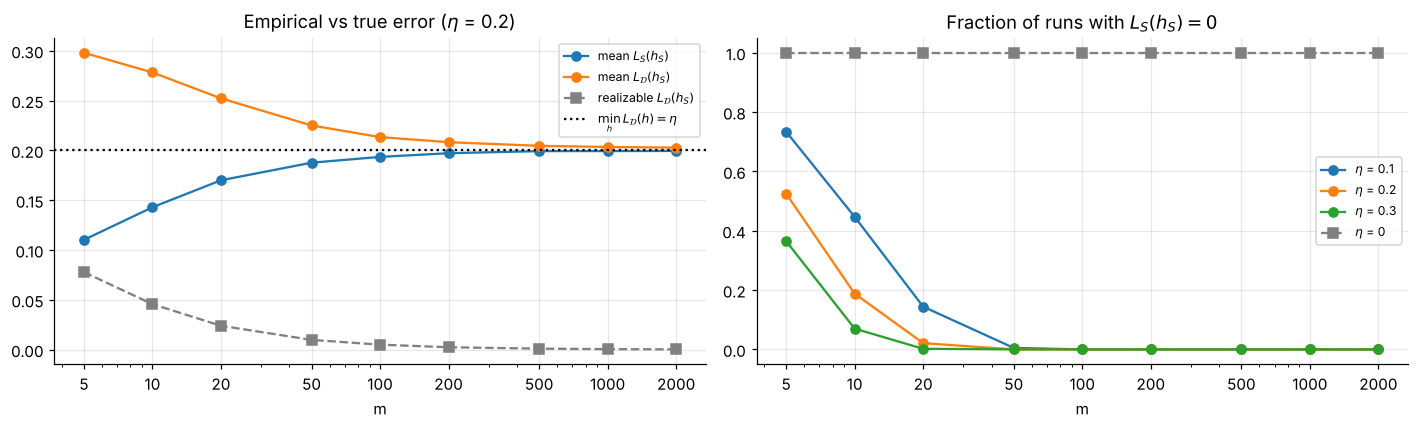

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
emp = [res_agn[ETA][m]["emp"].mean() for m in M_EXT]
tr  = [res_agn[ETA][m]["true"].mean() for m in M_EXT]
ax.plot(M_EXT, emp, "o-", label=r"mean $L_S(h_S)$")
ax.plot(M_EXT, tr,  "o-", label=r"mean $L_{\mathcal{D}}(h_S)$")
ax.plot(M_EXT, [res_real_ext[m]["true"].mean() for m in M_EXT], "s--", color="gray",
        label=r"realizable $L_{\mathcal{D}}(h_S)$")
ax.axhline(ETA, color="k", ls=":", label=r"$\min_h L_{\mathcal{D}}(h) = \eta$")
ax.set_xscale("log"); ax.set_xticks(M_EXT, M_EXT); ax.set_xlabel("m")
ax.set_title(f"Empirical vs true error ($\\eta$ = {ETA})"); ax.legend(fontsize=8)

ax = axes[1]
for eta in ETAS:
    ax.plot(M_EXT, [(res_agn[eta][m]["emp"] == 0).mean() for m in M_EXT], "o-", label=f"$\\eta$ = {eta}")
ax.plot(M_EXT, [(res_real_ext[m]["emp"] == 0).mean() for m in M_EXT], "s--", color="gray", label="$\\eta$ = 0")
ax.set_xscale("log"); ax.set_xticks(M_EXT, M_EXT); ax.set_xlabel("m")
ax.set_title(r"Fraction of runs with $L_S(h_S) = 0$"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.**

* **For small $m$, yes — by chance.** With 5 points, there is a good probability that the flipped labels still look consistent with *some* threshold (e.g. a flip on the "right" side of the boundary, or no flip at all). Then ERM reaches $L_S = 0$… while its true error is at least $\eta$. This is **overfitting the noise**.
* **For larger $m$, no.** The probability that $L_S(h_S) = 0$ collapses to 0 (already for $m \approx 50$ with $\eta = 0.2$), and the more noise, the faster. Every hypothesis then misclassifies about a fraction $\eta$ of the sample, and $L_S(h_S)$ converges to $\eta$, **from below**.
* $L_S(h_S)$ underestimates $L_{\mathcal{D}}(h_S)$ (ERM chooses the threshold that best fits *this* sample, including some of its noise). The gap is large for small $m$ and vanishes as $m$ grows: both errors converge to $\eta$ — not to 0 as in the realizable case (grey curve).

### 5.2 Does increasing $m$ still improve generalization? — Estimating $\Pr(L(h)>\varepsilon)$

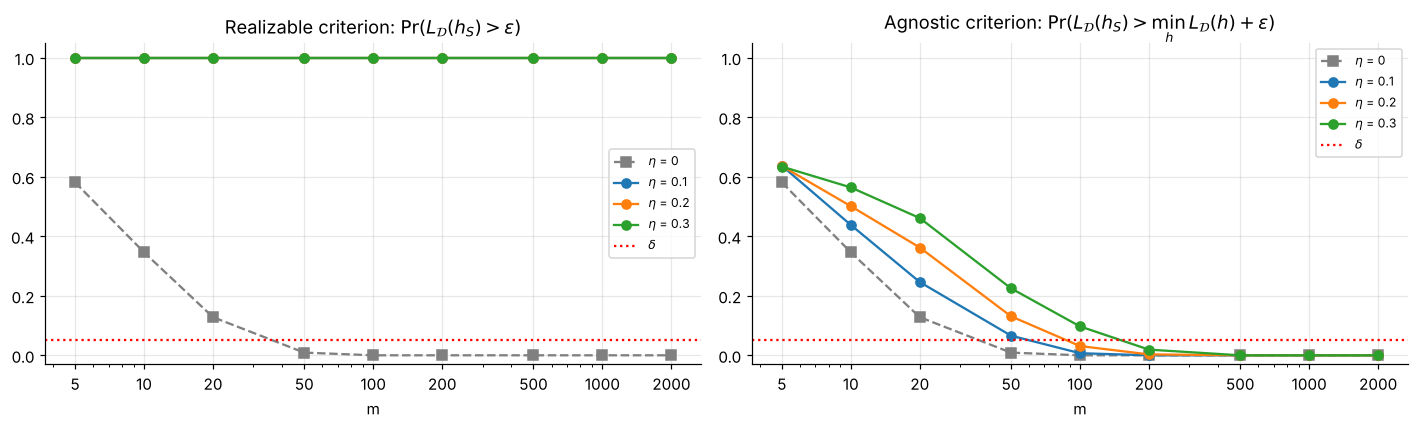

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.plot(M_EXT, [(res_real_ext[m]["true"] > EPS).mean() for m in M_EXT], "s--", color="gray", label="$\\eta$ = 0")
for eta in ETAS:
    ax.plot(M_EXT, [(res_agn[eta][m]["true"] > EPS).mean() for m in M_EXT], "o-", label=f"$\\eta$ = {eta}")
ax.axhline(DELTA, color="red", ls=":", label=r"$\delta$")
ax.set_xscale("log"); ax.set_xticks(M_EXT, M_EXT); ax.set_xlabel("m"); ax.set_ylim(-0.03, 1.05)
ax.set_title(r"Realizable criterion: $\Pr(L_{\mathcal{D}}(h_S) > \varepsilon)$"); ax.legend(fontsize=8)

ax = axes[1]
ax.plot(M_EXT, [(res_real_ext[m]["true"] > EPS).mean() for m in M_EXT], "s--", color="gray", label="$\\eta$ = 0")
for eta in ETAS:
    ax.plot(M_EXT, [(res_agn[eta][m]["true"] - res_agn[eta][m]["best"] > EPS).mean() for m in M_EXT], "o-", label=f"$\\eta$ = {eta}")
ax.axhline(DELTA, color="red", ls=":", label=r"$\delta$")
ax.set_xscale("log"); ax.set_xticks(M_EXT, M_EXT); ax.set_xlabel("m"); ax.set_ylim(-0.03, 1.05)
ax.set_title(r"Agnostic criterion: $\Pr(L_{\mathcal{D}}(h_S) > \min_h L_{\mathcal{D}}(h) + \varepsilon)$")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [19]:
# Smallest m of the grid such that the agnostic criterion is satisfied, per noise level
m_grid = [5, 10, 20, 30, 50, 75, 100, 150, 200, 300, 400, 500]
print(f"Smallest m with Pr(L(h_S) - min L > {EPS}) <= {DELTA}  (N = {N_REP} runs, grid {m_grid})\n")
for eta in [0.0] + ETAS:
    res = run_experiment(m_grid, eta, n_test=50_000)
    p = np.array([(res[m]["true"] - res[m]["best"] > EPS).mean() for m in m_grid])
    m_ok = next((m for m, pi in zip(m_grid, p) if pi <= DELTA), None)
    print(f"eta = {eta:.1f} :  m >= {m_ok}")

Smallest m with Pr(L(h_S) - min L > 0.05) <= 0.05  (N = 1000 runs, grid [5, 10, 20, 30, 50, 75, 100, 150, 200, 300, 400, 500])



eta = 0.0 :  m >= 30


eta = 0.1 :  m >= 75


eta = 0.2 :  m >= 100


eta = 0.3 :  m >= 150


**Interpretation.**

* **The realizable criterion $\Pr(L(h_S) > \varepsilon)$ is now useless:** the three noisy curves are superimposed at 1 (left plot) — it equals 1 for every $m$ as soon as $\eta > \varepsilon$, because *no* hypothesis can have an error below $\eta$. Adding examples cannot fix this: the error $\eta$ is due to the noise in the labels, not to the learner. This is why the realizable PAC definition must be relaxed.
* **The agnostic criterion is satisfied:** the probability that ERM is more than $\varepsilon$ worse than the best hypothesis of $\mathcal{H}$ decreases to 0, and falls below $\delta$ for a large enough $m$. So **yes, increasing $m$ still improves generalization** — but towards $\eta$, not towards 0.
* **Noise has a cost in samples:** the required $m$ grows with $\eta$ (in the table above: about 30 examples for $\eta = 0$, 75 for $\eta = 0.1$, 100 for $\eta = 0.2$ and 150 for $\eta = 0.3$). Near the boundary, noisy labels make the optimal threshold harder to locate, as seen on the flat empirical-error curve in Section 2.

### 5.3 Rate of convergence of the excess risk

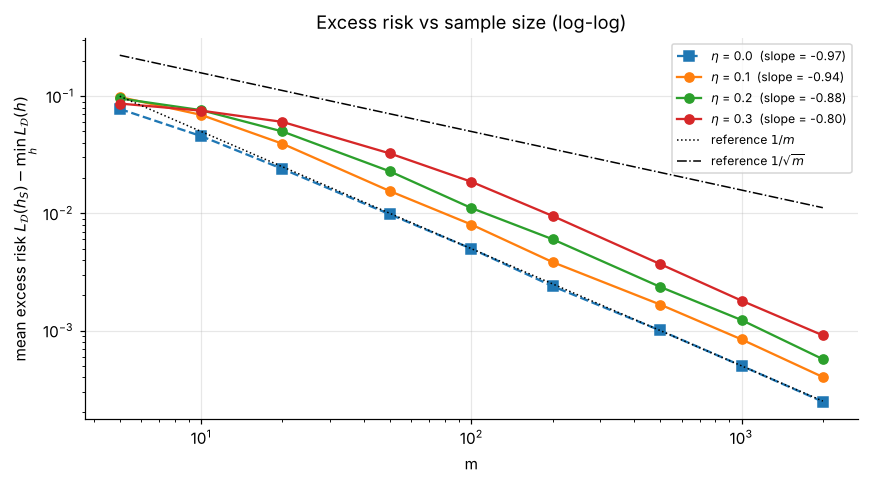

In [20]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ms = np.array(M_EXT)
for eta, res, style in [(0.0, res_real_ext, "s--")] + [(e, res_agn[e], "o-") for e in ETAS]:
    excess = np.array([(res[m]["true"] - res[m]["best"]).mean() for m in M_EXT])
    excess = np.maximum(excess, 1e-5)
    slope = np.polyfit(np.log(ms), np.log(excess), 1)[0]
    ax.loglog(ms, excess, style, label=f"$\\eta$ = {eta}  (slope = {slope:.2f})")
ax.loglog(ms, 0.5 / ms, "k:", lw=1, label=r"reference $1/m$")
ax.loglog(ms, 0.5 / np.sqrt(ms), "k-.", lw=1, label=r"reference $1/\sqrt{m}$")
ax.set_xlabel("m"); ax.set_ylabel(r"mean excess risk $L_{\mathcal{D}}(h_S) - \min_h L_{\mathcal{D}}(h)$")
ax.set_title("Excess risk vs sample size (log-log)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.**

* For every noise level the excess risk keeps **decreasing as $m$ grows**: ERM converges to the best hypothesis of $\mathcal{H}$ (agnostic PAC learnability, guaranteed here because $\mathcal{H}$ has VC-dimension 1).
* For a fixed $m$, the excess risk is **larger when $\eta$ is larger**: noise slows learning down, by a constant factor in this problem.
* The observed slopes lie between $-0.8$ and $-1$: far steeper than the $-0.5$ of a $1/\sqrt{m}$ rate, i.e. close to a $1/m$ rate even with noise (the slope gets slightly flatter as $\eta$ grows because, for small $m$, the noisy curves are still in a pre-asymptotic regime). This is better than the worst-case agnostic guarantee, whose sample complexity is in $O\big((d + \ln(1/\delta))/\varepsilon^2\big)$ (rate $1/\sqrt{m}$) instead of $O\big((d + \ln(1/\delta))/\varepsilon\big)$ in the realizable case. The reason is that our noise is *benign*: $\eta$ is constant and bounded away from $1/2$, so the label still indicates the correct class with probability $1-\eta > 1/2$ everywhere. The $1/\varepsilon^2$ rate is a **distribution-free worst case** (e.g. when $\Pr(y=1\mid x)$ is close to $1/2$ near the boundary), which a single favourable distribution does not have to reach. As $\eta \to 1/2$, the problem becomes harder and harder.

### 5.4 Answers to the three questions

**1. Can the empirical error still reach zero?**
Only by chance, for very small samples. With $\eta = 0.2$, ERM reaches $L_S(h_S) = 0$ in about 52 % of the runs for $m = 5$, 19 % for $m = 10$, 2 % for $m = 20$ and never for $m \ge 50$ (Section 5.1). When it happens, the true error is still at least $\eta$: a zero empirical error is then a sign of overfitting the noise, not of a good hypothesis. For large $m$, $L_S(h_S) \to \eta > 0$: no threshold can explain noisy labels perfectly. In the realizable setting, on the contrary, $L_S(h_S) = 0$ in 100 % of the runs, for every $m$.

**2. Does increasing the number of training examples still improve the generalization performance?**
Yes, but the limit is different. The true error decreases from $0.298$ ($m = 5$) to $0.203$ ($m = 2000$) for $\eta = 0.2$: it converges to $\eta = \min_{h\in\mathcal{H}} L_\mathcal{D}(h)$, not to 0. What vanishes is the *excess risk* $L_\mathcal{D}(h_S) - \min_h L_\mathcal{D}(h)$ (from $\approx 0.096$ to $\approx 0.0006$), and $\Pr\big(L_\mathcal{D}(h_S) > \min_h L_\mathcal{D}(h) + \varepsilon\big)$ goes below $\delta$ for $m \ge 100$ (Sections 5.2–5.3). The gain is slower than without noise: more examples are needed for the same $(\varepsilon, \delta)$, and the larger $\eta$, the more examples are needed.

**3. How do your observations relate to the PAC and Agnostic PAC learning frameworks introduced during the lectures?**

* *PAC (realizable) framework:* it assumes $\exists h^\star \in \mathcal{H}$ with $L_\mathcal{D}(h^\star) = 0$ and asks $\Pr(L_\mathcal{D}(h_S) > \varepsilon) \le \delta$ for $m \ge m_\mathcal{H}(\varepsilon,\delta)$. Our noiseless experiments match it exactly: ERM is consistent, the probability decreases exponentially in $m$ and stays below the bound $2(1-\varepsilon)^m$, i.e. $m_\mathcal{H}(\varepsilon, \delta) \le \lceil \ln(2/\delta)/\varepsilon \rceil = 74$.
* *With noise, the realizability assumption is violated:* $\Pr(L_\mathcal{D}(h_S) > \varepsilon) = 1$ for every $m$ when $\eta > \varepsilon$, so the PAC guarantee cannot hold, whatever the number of examples.
* *Agnostic PAC framework:* it only asks the learner to compete with the best hypothesis of the class, $\Pr\big(L_\mathcal{D}(h_S) > \min_{h\in\mathcal{H}} L_\mathcal{D}(h) + \varepsilon\big) \le \delta$. This is exactly what we observe: ERM satisfies this criterion for $m$ large enough. This is explained by **uniform convergence**: for large $m$, $L_S(h)$ is close to $L_\mathcal{D}(h)$ for *all* thresholds simultaneously (class of VC-dimension 1), so minimizing $L_S$ nearly minimizes $L_\mathcal{D}$ — we see it in the convergence of both curves to $\eta$.
* *Sample complexity:* the lectures give $O(1/\varepsilon)$ in the realizable case and $O(1/\varepsilon^2)$ in the agnostic case (up to $d$ and $\ln(1/\delta)$ terms). We do observe that noise increases the number of samples needed (30 → 75 → 100 → 150 examples when $\eta$ goes from 0 to 0.3). The empirical rate stays close to $1/m$ because our noise is benign ($\eta$ constant, far from $1/2$); the $1/\varepsilon^2$ rate is a distribution-free worst case, valid for *every* distribution, so it is an upper bound and not necessarily what one particular distribution produces.

## 6. Conclusion — PAC vs Agnostic PAC

| | **Realizable (PAC)** | **Agnostic PAC** ($\eta > 0$) |
|---|---|---|
| Best achievable error $\min_{h} L_{\mathcal{D}}(h)$ | $0$ | $\eta$ (here $0.1$ / $0.2$ / $0.3$) |
| Empirical error of ERM | always exactly $0$ | $> 0$ as soon as $m$ is not tiny; $\to \eta$ from below |
| $L_S$ vs $L_{\mathcal{D}}$ | $L_S = 0$ underestimates $L_{\mathcal{D}}$, gap $\approx 1/m$ | $L_S$ underestimates $L_{\mathcal{D}}$ (fits part of the noise), gap $\to 0$ |
| $\Pr(L(h_S) > \varepsilon)$ | $\to 0$ exponentially, $\le \delta$ from $m \approx 50$ | $= 1$ for all $m$ when $\eta > \varepsilon$ — criterion meaningless |
| $\Pr(L(h_S) > \min_h L + \varepsilon)$ | same as above | $\to 0$, but more samples are needed when $\eta$ increases |
| Theoretical sample complexity | $O\!\left(\frac{d+\ln(1/\delta)}{\varepsilon}\right)$ | $O\!\left(\frac{d+\ln(1/\delta)}{\varepsilon^2}\right)$ (worst case) |

**Summary of the observations.**

1. In the **realizable** setting, ERM always finds a consistent threshold ($L_S = 0$), and its true error goes to 0: the probability of exceeding $\varepsilon$ decreases exponentially with $m$ and stays below the theoretical bound $2(1-\varepsilon)^m$. Thresholds are PAC learnable.
2. With **label noise**, the empirical error can reach 0 only by chance on very small samples (overfitting the noise); otherwise it stays near $\eta$. No amount of data can bring the true error below $\eta$, so the realizable criterion fails for every $m$.
3. Increasing $m$ **still improves generalization**, but the target becomes **the best hypothesis of the class** rather than zero error: this is exactly the agnostic PAC definition, where the guarantee is *relative* to $\min_{h\in\mathcal{H}} L_{\mathcal{D}}(h)$.
4. Noise has a **price in samples**: for the same $(\varepsilon, \delta)$, more examples are needed as $\eta$ grows. In our benign-noise problem the convergence remains fast ($\approx 1/m$); the slower $1/\varepsilon^2$ dependence of agnostic PAC theory is a distribution-free worst case.

In short: **PAC learning asks "can we get close to perfect?"; agnostic PAC learning asks "can we get close to the best that our hypothesis class allows?"** — and our experiments show that ERM over thresholds answers yes to both questions, in their respective settings.